In [53]:
pip install louvain

In [1]:
import os
import glob
import pickle
import pandas as pd
import numpy as np

from pathlib import Path

# Project root = folder that holds DATA/, RESOURCES/ and DATABASES/.
# Works whether Jupyter is started in the repo root or in notebooks/.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)  # Set Working Directory
cwd = os.getcwd()
print("Current working directory (using os module):", cwd)

from dask.diagnostics import ProgressBar

from arboreto.utils import load_tf_names
from arboreto.algo import grnboost2

from ctxcore.rnkdb import FeatherRankingDatabase as RankingDatabase
from pyscenic.utils import modules_from_adjacencies, load_motifs
from pyscenic.prune import prune2df, df2regulons
from pyscenic.aucell import aucell
from scipy.io import mmread

import seaborn as sns
import matplotlib.pyplot as plt

DATA_FOLDER = str(ROOT / 'DATA')
RESOURCES_FOLDER = str(ROOT / 'RESOURCES')
DATABASE_FOLDER = str(ROOT / 'DATABASES')
DATABASES_GLOB = os.path.join(DATABASE_FOLDER, "hg38_10kbp_up_10kbp_down_full_tx_v10_clust.genes_vs_motifs.rankings.feather") 
MOTIF_ANNOTATIONS_FNAME = os.path.join(RESOURCES_FOLDER, "motifs-v10nr_clust-nr.hgnc-m0.001-o0.0.tbl") # Motif2TF
TFS_FNAME = os.path.join(RESOURCES_FOLDER, 'allTFs_hg38.txt')
SC_EXP_FNAME = os.path.join(RESOURCES_FOLDER, "Blastoid.1day21.data.csv") # Single Cell RNA Data
CELL_TYPE_FNAME = os.path.join(RESOURCES_FOLDER, "Blastoid.1.cell_types.csv") # Use to make UMAP of cell types
REGULONS_FNAME = os.path.join(DATA_FOLDER, "regulons.p")
MOTIFS_FNAME = os.path.join(DATA_FOLDER, "motifs.csv")

Current working directory (using os module): C:\Users\igaml


In [4]:
ex_matrix = pd.read_csv(SC_EXP_FNAME, header=0, index_col=0).T
print(ex_matrix.columns)
ex_matrix.shape



Index(['SAMD11', 'NOC2L', 'KLHL17', 'PLEKHN1', 'HES4', 'ISG15', 'AGRN',
       'RNF223', 'C1orf159', 'TTLL10',
       ...
       'WDYHV1', 'WFDC6', 'WRB', 'XACT', 'YARS', 'Z69720.2', 'ZFAS1', 'ZFY',
       'ZNF286B', 'ZNF812P'],
      dtype='object', length=18078)


(4730, 18078)

In [5]:
# Assign cell names

cell_types_df = pd.read_csv(CELL_TYPE_FNAME, header=None)

cell_type_mapping = dict(zip(cell_types_df[0], cell_types_df[1]))

# (Optional) Modify the mapping to account for the difference in formatting
adjusted_mapping = {key.replace('-1', '.1'): value for key, value in cell_type_mapping.items()}

ex_matrix.rename(index=adjusted_mapping, inplace=True)

print(ex_matrix.head(10))  # Print the first 10 rows

        SAMD11     NOC2L  KLHL17  PLEKHN1      HES4     ISG15  AGRN  RNF223  \
bEPI       0.0  0.925712     0.0      0.0  0.000000  0.322747   0.0     0.0   
bEVT       0.0  0.297206     0.0      0.0  0.000000  0.297206   0.0     0.0   
bExMes     0.0  0.000000     0.0      0.0  0.000000  0.400722   0.0     0.0   
bEVT       0.0  0.421482     0.0      0.0  0.000000  0.717077   0.0     0.0   
bAdMes     0.0  0.000000     0.0      0.0  0.000000  0.000000   0.0     0.0   
bAdMes     0.0  0.000000     0.0      0.0  0.584464  0.950908   0.0     0.0   
bEVT       0.0  0.000000     0.0      0.0  0.558728  0.000000   0.0     0.0   
bEVT       0.0  0.000000     0.0      0.0  0.278028  0.000000   0.0     0.0   
bCTB       0.0  0.000000     0.0      0.0  0.000000  0.000000   0.0     0.0   
bCTB       0.0  0.000000     0.0      0.0  0.000000  1.128268   0.0     0.0   

        C1orf159  TTLL10  ...  WDYHV1  WFDC6  WRB  XACT  YARS  Z69720.2  \
bEPI    0.000000     0.0  ...     0.0    0.0  0.0   0.0

In [6]:
tf_names = load_tf_names(TFS_FNAME)

db_fnames = glob.glob(DATABASES_GLOB)
def name(fname):
    return os.path.splitext(os.path.basename(fname))[0]
dbs = [RankingDatabase(fname=fname, name=name(fname)) for fname in db_fnames]
dbs

[FeatherRankingDatabase(name="hg38_10kbp_up_10kbp_down_full_tx_v10_clust.genes_vs_motifs.rankings")]

In [7]:
adjacencies = grnboost2(ex_matrix, tf_names=tf_names, verbose=True)

preparing dask client
parsing input
creating dask graph
4 partitions
computing dask graph


C:\Users\igaml\anaconda3\envs\pyscenic_env\lib\site-packages\distributed\client.py:3108: UserWarning: Sending large graph of size 631.53 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(


shutting down client and local cluster
finished


In [8]:
modules = list(modules_from_adjacencies(adjacencies, ex_matrix))


2024-11-19 17:15:42,809 - pyscenic.utils - INFO - Calculating Pearson correlations.

2024-11-19 17:15:43,162 - pyscenic.utils - WARNING - Note on correlation calculation: the default behaviour for calculating the correlations has changed after pySCENIC verion 0.9.16. Previously, the default was to calculate the correlation between a TF and target gene using only cells with non-zero expression values (mask_dropouts=True). The current default is now to use all cells to match the behavior of the R verision of SCENIC. The original settings can be retained by setting 'rho_mask_dropouts=True' in the modules_from_adjacencies function, or '--mask_dropouts' from the CLI.
	Dropout masking is currently set to [False].

2024-11-19 17:16:20,864 - pyscenic.utils - INFO - Creating modules.


In [ ]:
# Calculate a list of enriched motifs and the corresponding target genes for all modules.
with ProgressBar():
    df = prune2df(dbs, modules, MOTIF_ANNOTATIONS_FNAME)

# Create regulons from this table of enriched motifs.
regulons = df2regulons(df)

# Save the enriched motifs and the discovered regulons to disk.
df.to_csv(MOTIFS_FNAME)
with open(REGULONS_FNAME, "wb") as f:
    pickle.dump(regulons, f)

[                                        ] | 0% Completed | 512.80 ss

In [ ]:
df = load_motifs(MOTIFS_FNAME)
with open(REGULONS_FNAME, "rb") as f:
    regulons = pickle.load(f)

In [ ]:
column_sums = pd.Series(ex_matrix.sum(axis=0))
print((column_sums > 150).value_counts())
ex_matrix_1 = ex_matrix.loc[:, column_sums > 150]
print(ex_matrix_1.shape)

C:\Users\igaml\anaconda3\envs\pyscenic_env\lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
C:\Users\igaml\anaconda3\envs\pyscenic_env\lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


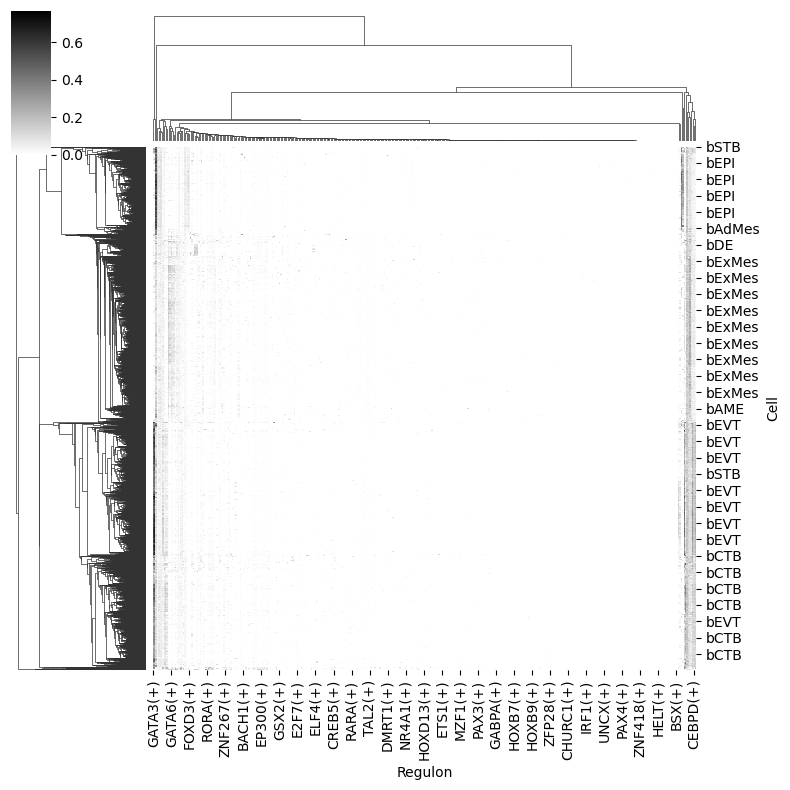

In [11]:
auc_mtx = aucell(ex_matrix, regulons, num_workers=4)
sns.clustermap(auc_mtx, figsize=(8,8), cmap='binary') # Change color to black and white

In [20]:
print(auc_mtx.shape)
print(auc_mtx.head(n=5))




(4730, 392)
Regulon  ALX3(+)  ALX4(+)  AR(+)  ARID3A(+)  ARID5A(+)  ARNTL(+)  ARX(+)  \
Cell                                                                       
bEPI         0.0      0.0    0.0   0.000000        0.0       0.0     0.0   
bEVT         0.0      0.0    0.0   0.376408        0.0       0.0     0.0   
bExMes       0.0      0.0    0.0   0.087642        0.0       0.0     0.0   
bEVT         0.0      0.0    0.0   0.294136        0.0       0.0     0.0   
bAdMes       0.0      0.0    0.0   0.000000        0.0       0.0     0.0   

Regulon  ASH2L(+)  ATF1(+)  ATF2(+)  ...  ZNF704(+)  ZNF729(+)  ZNF773(+)  \
Cell                                 ...                                    
bEPI          0.0      0.0      0.0  ...   0.000000        0.0        0.0   
bEVT          0.0      0.0      0.0  ...   0.003229        0.0        0.0   
bExMes        0.0      0.0      0.0  ...   0.003863        0.0        0.0   
bEVT          0.0      0.0      0.0  ...   0.004235        0.0        

In [13]:
# UMAP Creation with scanpy

import scanpy as sc
import loompy as lp
#from MulticoreTSNE import MulticoreTSNE as TSNE
import umap
import igraph
#import louvain

C:\Users\igaml\anaconda3\envs\pyscenic_env\lib\site-packages\loompy\bus_file.py:68: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  def twobit_to_dna(twobit: int, size: int) -> str:
C:\Users\igaml\anaconda3\envs\pyscenic_env\lib\site-packages\loompy\bus_file.py:85: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  def dna_to_twobit(dna: str) -> int:
C:\Users\igaml\ana

C:\Users\igaml\anaconda3\envs\pyscenic_env\lib\site-packages\anndata\_core\anndata.py:1838: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
C:\Users\igaml\anaconda3\envs\pyscenic_env\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


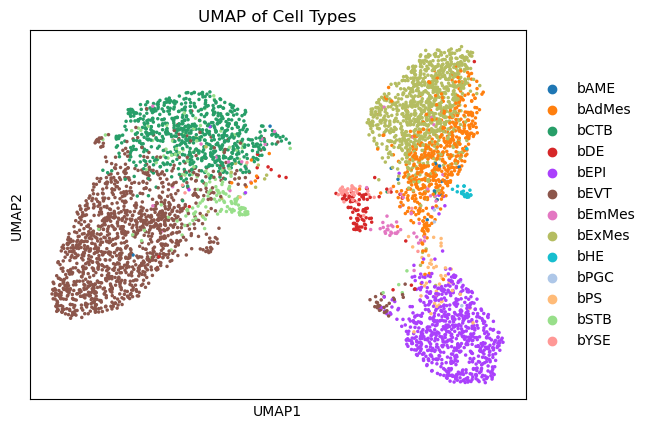

In [25]:
#Create UMAP of cells and regulons that shows expression levels of regulons
#Fig. 12 | Overview of cancer single cell transcriptomics experiments. (3 regulons that show expression data in heatmap)

adata = sc.AnnData(auc_mtx)
adata.obs['cell_type'] = adata.obs_names
sc.tl.pca(adata, svd_solver='arpack')
sc.pp.neighbors(adata)  # Compute the nearest neighbors
sc.tl.umap(adata)      # Perform UMAP
sc.pl.umap(adata, color='cell_type', title='UMAP of Cell Types')

C:\Users\igaml\anaconda3\envs\pyscenic_env\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


<Figure size 1000x800 with 0 Axes>

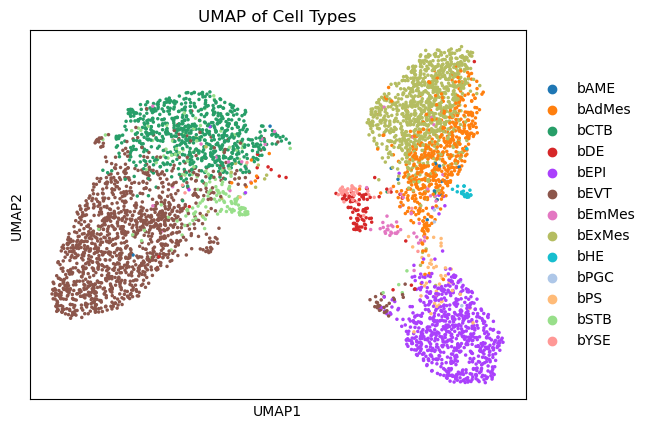

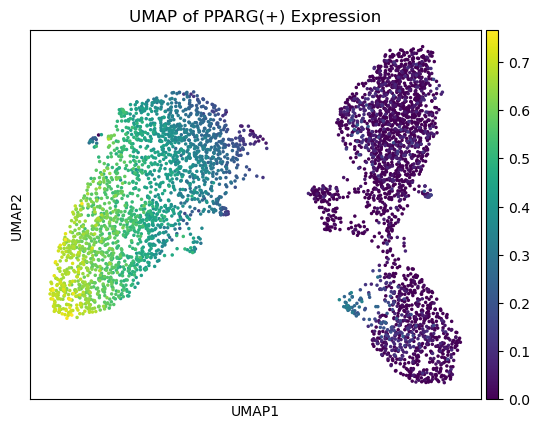

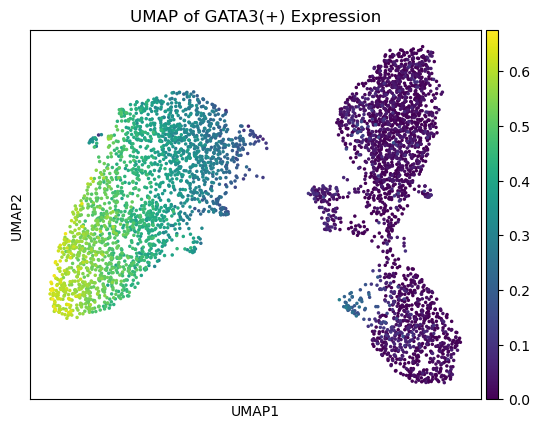

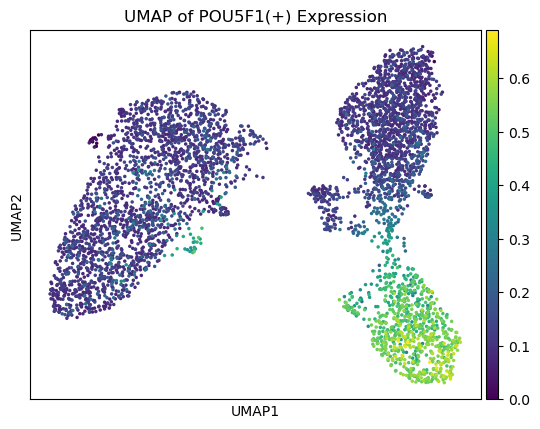

In [26]:
mean_expression = auc_mtx.mean(axis=0)
top_3_regulons = mean_expression.sort_values(ascending=False).head(3)
top_3_regulons_names = top_3_regulons.index

adata.obs['top_3_regulon_1'] = auc_mtx[top_3_regulons_names[0]]
adata.obs['top_3_regulon_2'] = auc_mtx[top_3_regulons_names[1]]
adata.obs['top_3_regulon_3'] = auc_mtx[top_3_regulons_names[2]]

plt.figure(figsize=(10, 8))
sc.pl.umap(adata, color='cell_type', title='UMAP of Cell Types', show=False)

# Plot UMAP for top regulon 1 expression
sc.pl.umap(adata, color='top_3_regulon_1', title=f'UMAP of {top_3_regulons_names[0]} Expression', show=False)

# Plot UMAP for top regulon 2 expression
sc.pl.umap(adata, color='top_3_regulon_2', title=f'UMAP of {top_3_regulons_names[1]} Expression', show=False)

# Plot UMAP for top regulon 3 expression
sc.pl.umap(adata, color='top_3_regulon_3', title=f'UMAP of {top_3_regulons_names[2]} Expression', show=True)


In [23]:
os.chdir(DATA_FOLDER)  # outputs below are written to DATA/
cwd = os.getcwd()
print("Current working directory (using os module):", cwd)

# path to unfiltered loom file 
f_loom_path_unfilt = "day21blastoid_unfiltered.loom" 

# # path to loom file with basic filtering applied (this will be created in the "initial filtering" step below). Optional.
f_loom_path_scenic = "day21blastoid_filtered_scenic.loom"

# path to anndata object, which will be updated to store Scanpy results as they are generated below
f_anndata_path = "anndata.h5ad"

# path to pyscenic output
f_pyscenic_output = "pyscenic_output.loom"

# loom output, generated from a combination of Scanpy and pySCENIC results:
f_final_loom = 'day21blastoid_scenic_integrated-output.loom'

Current working directory (using os module): C:\Workspace\DATA


In [51]:
sc.settings.verbosity = 3 # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.logging.print_versions()
sc.set_figure_params(dpi=150, fontsize=10, dpi_save=600)

-----
anndata     0.9.2
scanpy      1.9.8
-----
PIL                         10.4.0
anyio                       NA
arboreto                    NA
asttokens                   NA
attr                        23.1.0
attrs                       23.1.0
babel                       2.11.0
backcall                    0.2.0
backports                   NA
boltons                     NA
bottleneck                  1.3.7
brotli                      1.0.9
certifi                     2024.08.30
cffi                        1.17.1
charset_normalizer          3.3.2
click                       8.1.7
cloudpickle                 3.0.0
colorama                    0.4.6
comm                        0.2.1
ctxcore                     0.2.0
cycler                      0.10.0
cython_runtime              NA
cytoolz                     1.0.0
dask                        2023.5.0
dateutil                    2.9.0.post0
debugpy                     1.6.7
decorator                   5.1.1
defusedxml                  0.7.

In [25]:
# Set maximum number of jobs for Scanpy.
sc.settings.njobs = 20

In [27]:
# Reading in expression data: from a text file
adata = sc.read_text(SC_EXP_FNAME, delimiter=',', first_column_names=True)

In [28]:
# Write to an unfiltered loom file

row_attrs = { 
    "Gene": np.array(adata.var.index) ,
}
col_attrs = { 
    "CellID":  np.array(adata.obs.index) ,
    "nGene": np.array( np.sum(adata.X.transpose()>0 , axis=0)).flatten() ,
    "nUMI": np.array( np.sum(adata.X.transpose() , axis=0)).flatten() ,
}

lp.create( f_loom_path_unfilt, adata.X.transpose(), row_attrs, col_attrs )

In [29]:
# Initial/basic filtering

# read unfiltered data from a loom file
adata = sc.read_loom(f_loom_path_unfilt)

nCountsPerGene = np.sum(adata.X, axis=0)
nCellsPerGene = np.sum(adata.X>0, axis=0)

# Show info
print("Number of counts (in the dataset units) per gene:", nCountsPerGene.min(), " - " ,nCountsPerGene.max())
print("Number of cells in which each gene is detected:", nCellsPerGene.min(), " - " ,nCellsPerGene.max())



Number of counts (in the dataset units) per gene: 1515.6923  -  4233.4907
Number of cells in which each gene is detected: 1508  -  7999


In [30]:
nCells=adata.X.shape[0]

# pySCENIC thresholds
minCountsPerGene=3*.01*nCells # 3 counts in 1% of cells
print("minCountsPerGene: ", minCountsPerGene)

minSamples=.01*nCells # 1% of cells
print("minSamples: ", minSamples)

# simply compute the number of genes per cell (computers 'n_genes' column)
sc.pp.filter_cells(adata, min_genes=0)

minCountsPerGene:  542.34
minSamples:  180.78


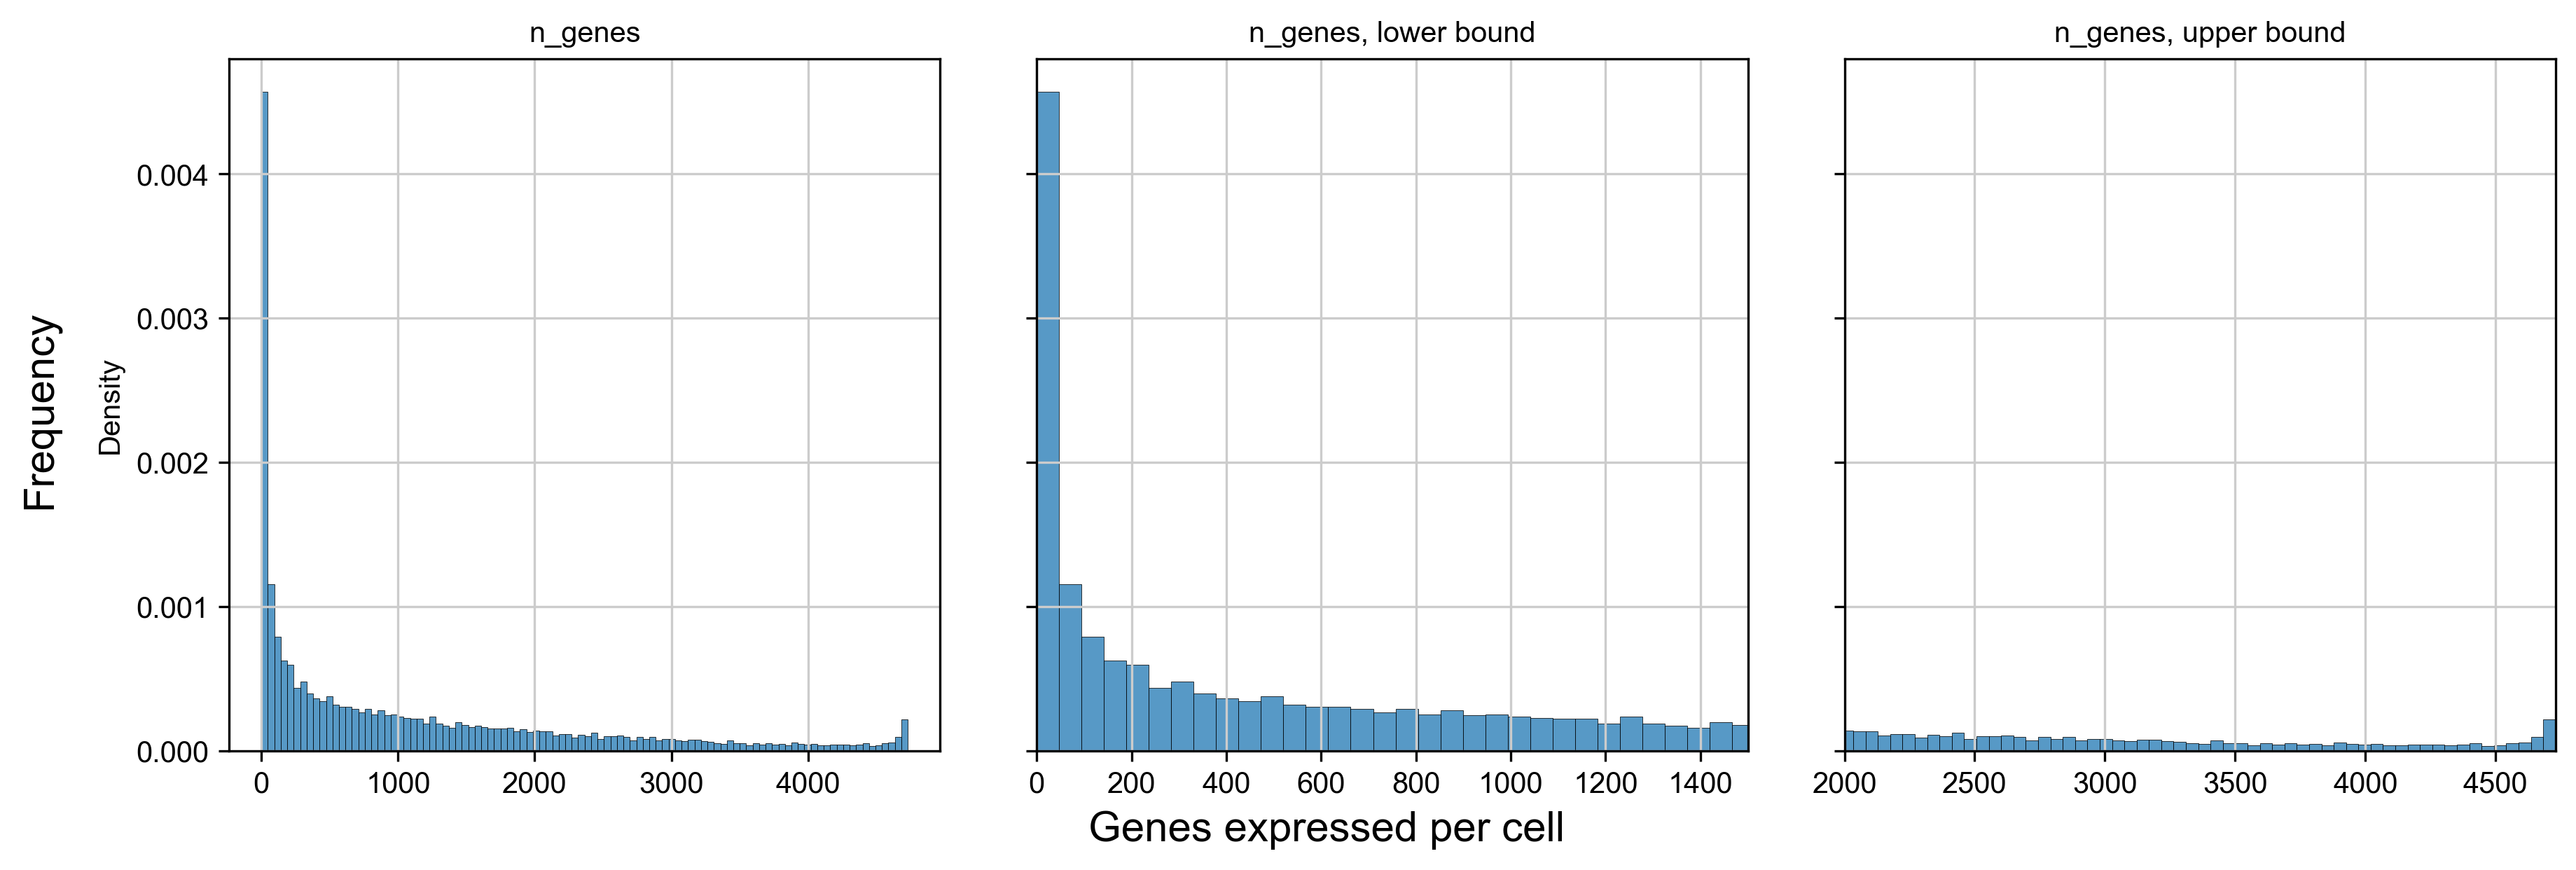

In [37]:
##Diagnostic plots, pre-filtering
##Number of genes expressed per cell
##No steps for mitochondrial genes included

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=True)

x = adata.obs['n_genes']
x_lowerbound = 1500
x_upperbound = 2000
nbins=100

sns.histplot(x, ax=ax1, stat='density', bins=nbins)
sns.histplot(x, ax=ax2, stat='density', bins=nbins)
sns.histplot(x, ax=ax3, stat='density', bins=nbins)

ax2.set_xlim(0,x_lowerbound)
ax3.set_xlim(x_upperbound, adata.obs['n_genes'].max() )

for ax in (ax1,ax2,ax3): 
  ax.set_xlabel('')

ax1.title.set_text('n_genes')
ax2.title.set_text('n_genes, lower bound')
ax3.title.set_text('n_genes, upper bound')

fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')
fig.text(0.5, 0.0, 'Genes expressed per cell', ha='center', va='center', size='x-large')

fig.tight_layout()

In [38]:
# Filtering
# initial cuts
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)


filtered out 6212 cells that have less than 200 genes expressed


In [39]:
adata = adata[adata.obs['n_genes'] < 4000, :]

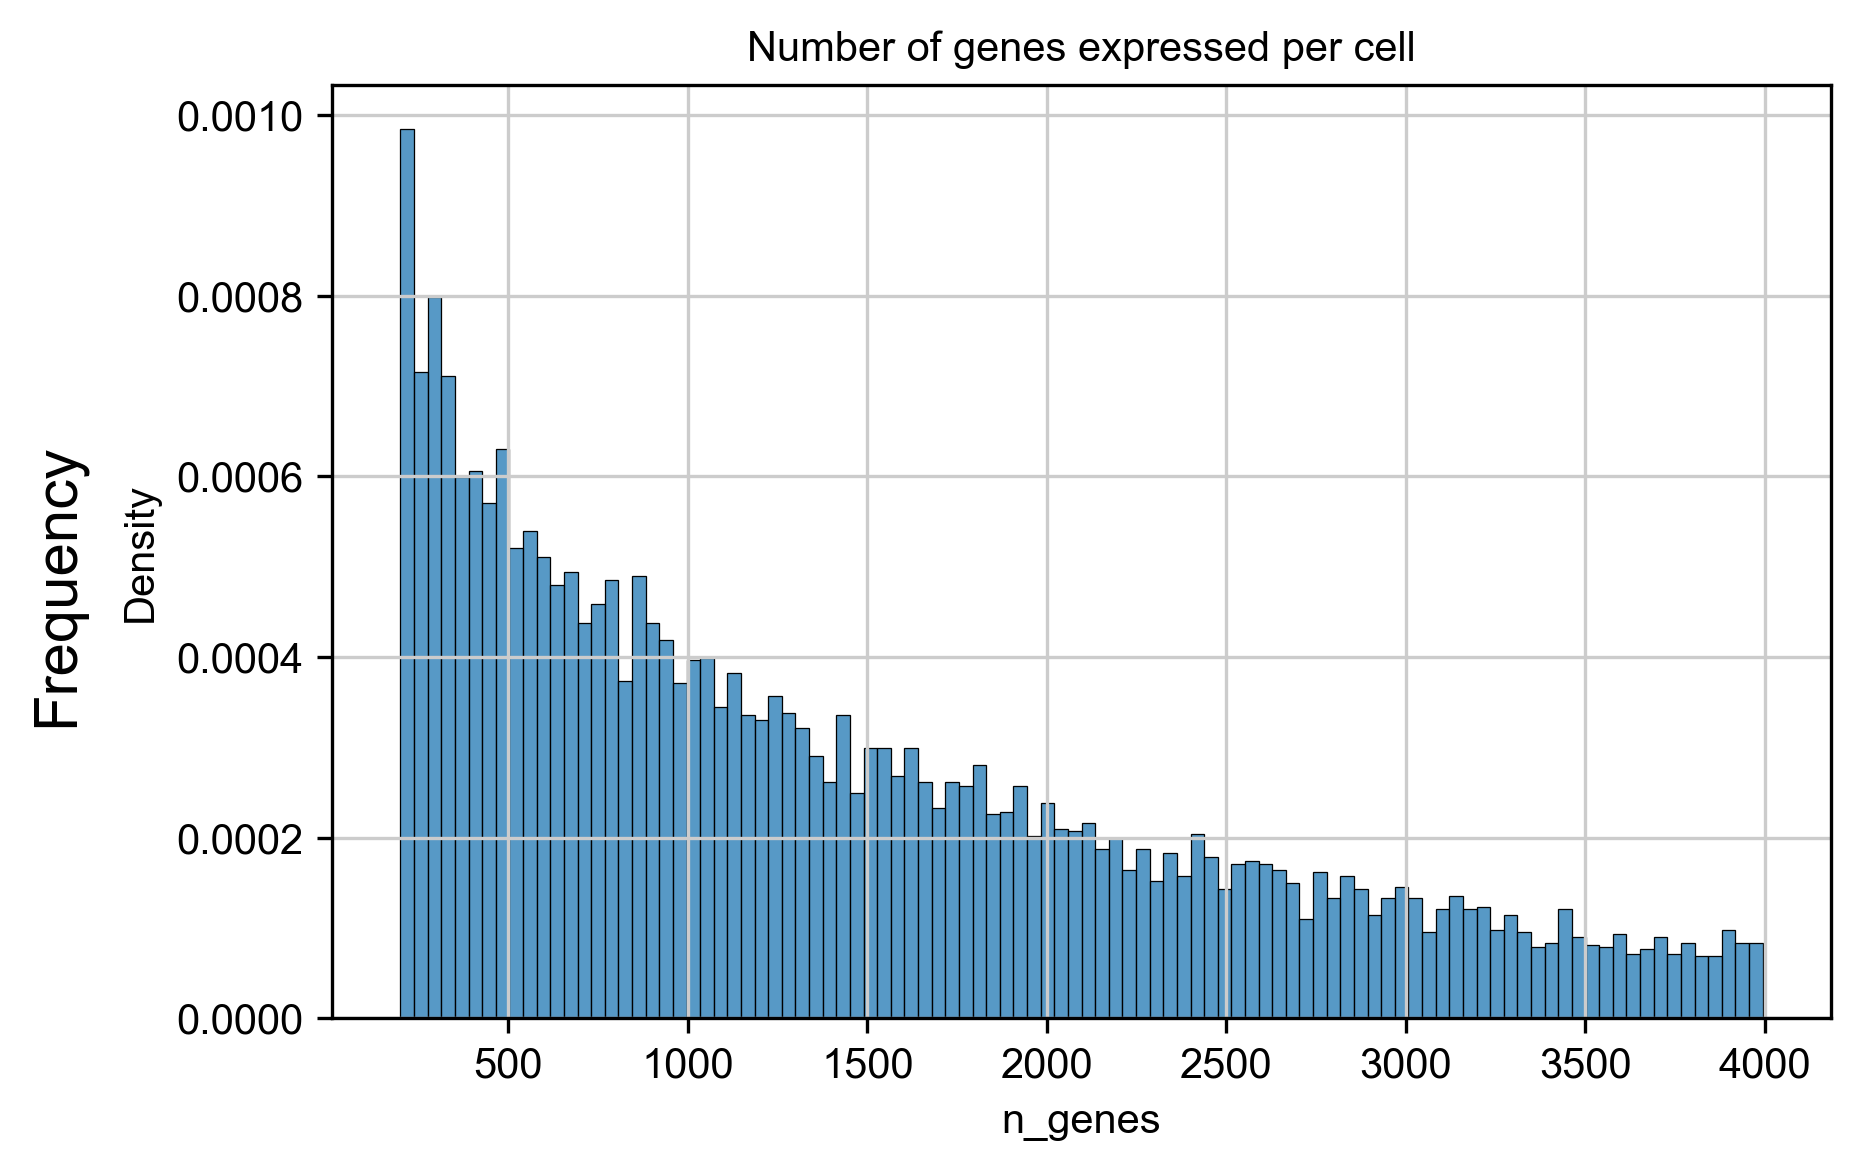

In [44]:
#Diagnostic plots, post filtering

fig, ax1 = plt.subplots(figsize=(6, 4), dpi=150)

# Plotting only the first distribution
sns.histplot(adata.obs['n_genes'], ax=ax1, stat='density', bins=100)

# Setting title for the plot
ax1.title.set_text('Number of genes expressed per cell')

# Adding a common y-axis label
fig.text(-0.01, 0.5, 'Frequency', ha='center', va='center', rotation='vertical', size='x-large')

# Adjust layout to ensure no overlap
fig.tight_layout()

# Save the figure to a file
fig.savefig('filtering_panel_postfilter_first_plot.pdf', dpi=600, bbox_inches='tight')

# Show the plot
plt.show()


In [45]:
# Finalize the selected filters
# Update the anndata file, to be used for further processing, clustering, visualization, etc..

adata.write( f_anndata_path )

# Output the basic filtered expression matrix to a loom file.
# create basic row and column attributes for the loom file:
row_attrs = {
    "Gene": np.array(adata.var_names) ,
}
col_attrs = {
    "CellID": np.array(adata.obs_names) ,
    "nGene": np.array( np.sum(adata.X.transpose()>0 , axis=0)).flatten() ,
    "nUMI": np.array( np.sum(adata.X.transpose() , axis=0)).flatten() ,
}
lp.create( f_loom_path_scenic, adata.X.transpose(), row_attrs, col_attrs)

normalizing by total count per cell
    finished (0:00:00): normalized adata.X and added    'n_counts', counts per cell before normalization (adata.obs)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


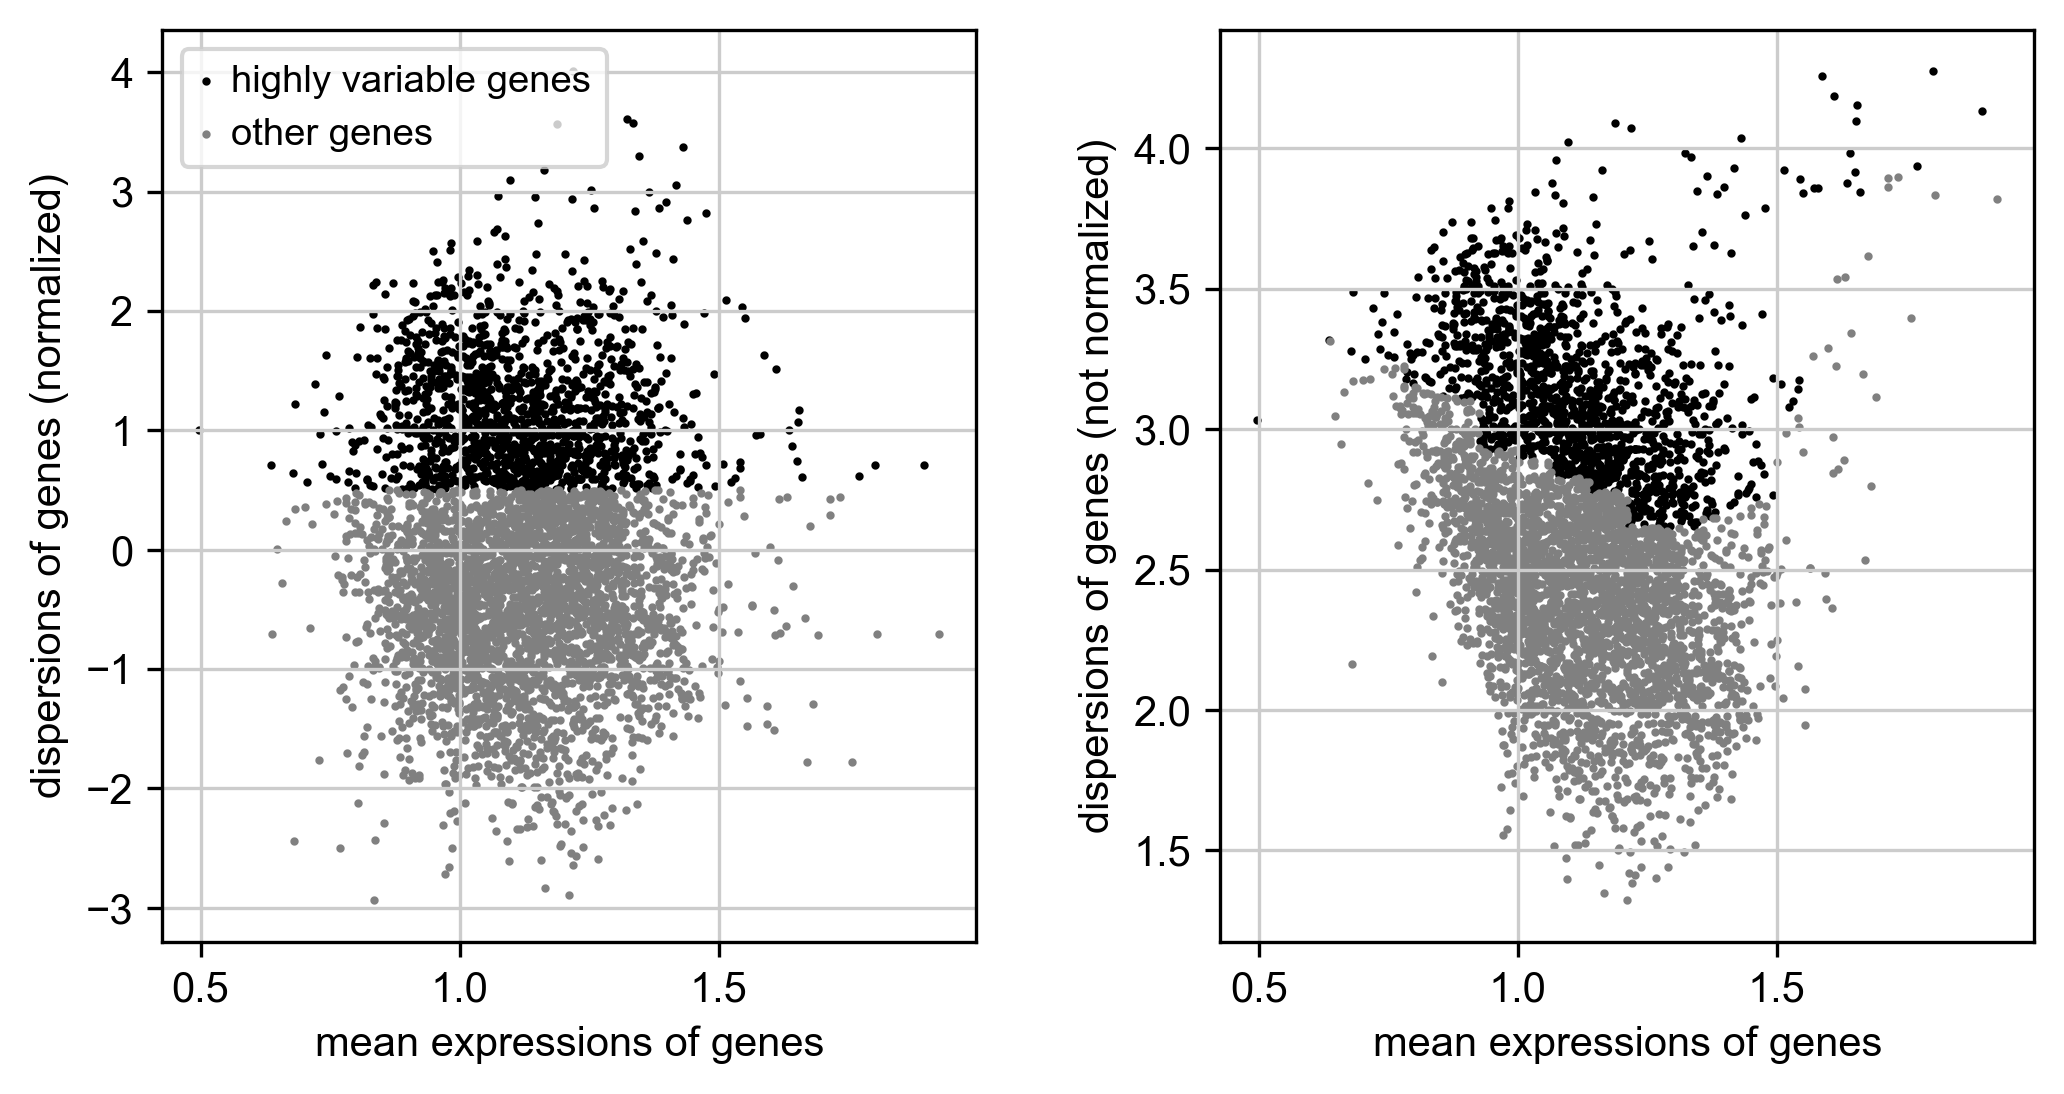

C:\Users\igaml\anaconda3\envs\pyscenic_env\lib\site-packages\scanpy\preprocessing\_simple.py:843: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


... as `zero_center=True`, sparse input is densified and may lead to large memory consumption


In [46]:
# save a copy of the raw data
adata.raw = adata

# Total-count normalize (library-size correct) to 10,000 reads/cell
sc.pp.normalize_per_cell(adata, counts_per_cell_after=1e4)

# log transform the data.
sc.pp.log1p(adata)

# identify highly variable genes.
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
sc.pl.highly_variable_genes(adata)

# keep only highly variable genes:
adata = adata[:, adata.var['highly_variable']]

# scale each gene to unit variance, clip values exceeding SD 10.
sc.pp.scale(adata, max_value=10)

# update the anndata file:
adata.write( f_anndata_path )

computing neighbors
    using 'X_pca' with n_pcs = 30
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:06)
running Louvain clustering
    using the "louvain" package of Traag (2017)
    finished: found 6 clusters and added
    'louvain', the cluster labels (adata.obs, categorical) (0:00:00)


C:\Users\igaml\anaconda3\envs\pyscenic_env\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


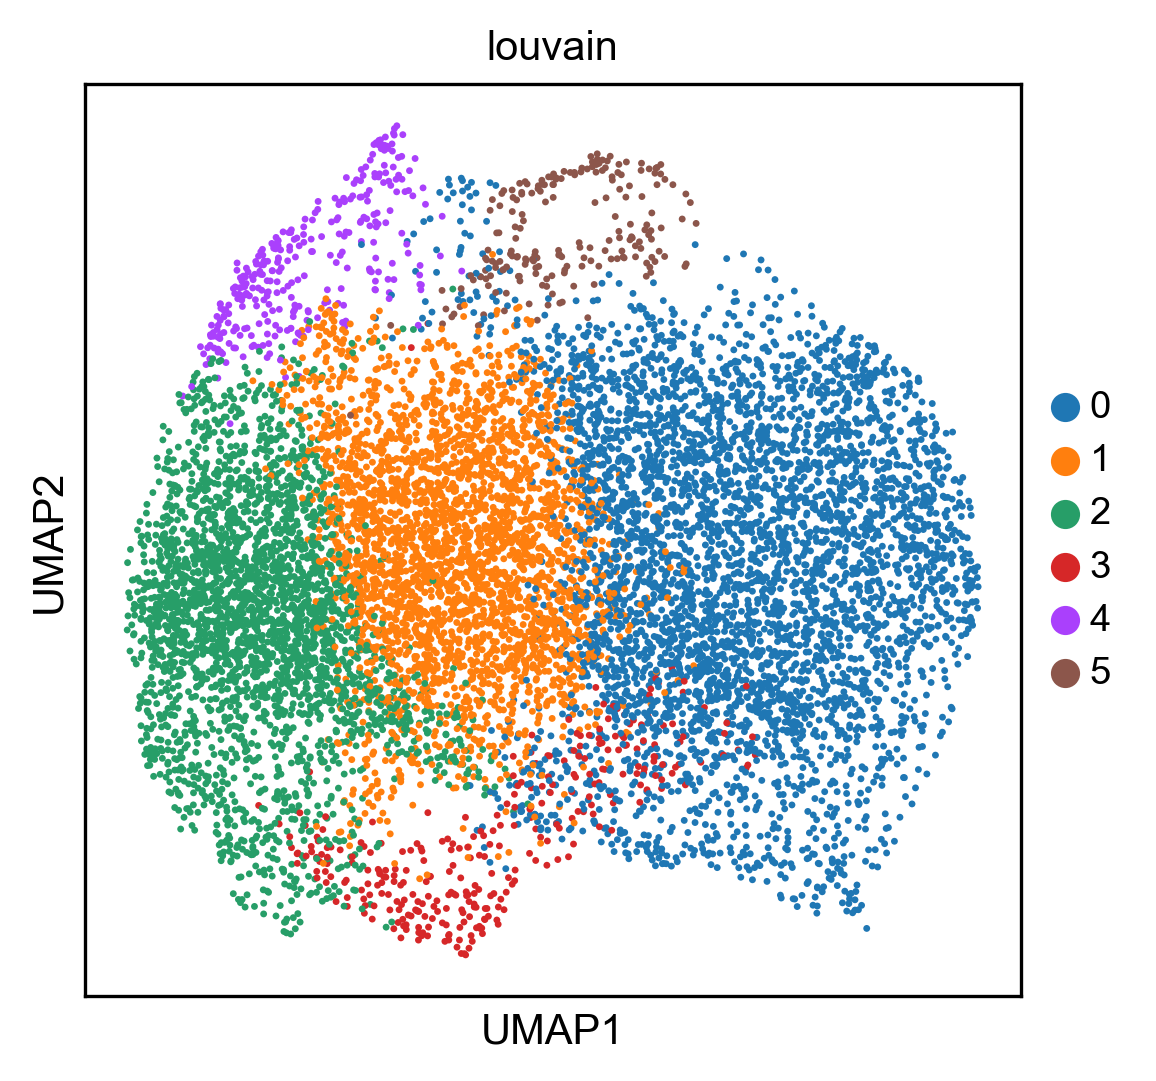

In [55]:
#Visualization of highly variable genes

# neighborhood graph of cells (determine optimal number of PCs here)
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30)
# compute UMAP
sc.tl.umap(adata)

# cluster the neighbourhood graph
sc.tl.louvain(adata,resolution=0.4)

sc.pl.umap(adata, color=['louvain'] ) #Color by Regulons